In [215]:
import pandas as pd
import os

print(os.getcwd())
print(os.listdir("data/"))

df = pd.read_csv("data/raw_members.csv")
df.head()

C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\Himalayan-Survivors
['cleaned_members.csv', 'himalayan_data_dictionary.csv', 'raw_members.csv', 'README.md']


C:\Users\AineC\AppData\Local\Temp\ipykernel_19868\2787635637.py:7: DtypeWarning: Columns (34: msmtdate3) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("data/raw_members.csv")


,expid,membid,peakid,myear,mseason,fname,lname,sex,yob,citizen,...,death,deathdate,deathtime,deathtype,deathhgtm,deathclass,msmtbid,msmtterm,hcn,mchksum
0,AMAD01101,2,AMAD,2001,Spring,Rohan,Buckley,M,1972.0,Australia,...,False,NaN,NaN,NaN,0,NaN,No summit bid,Did not climb or intent to summit,NaN,2439554
1,AMAD01101,1,AMAD,2001,Spring,Marc Cameron,Fairhead,M,1968.0,Australia,...,False,NaN,NaN,NaN,0,NaN,Aborted at high camp,"Bad conditions (deep snow, avalanches, falling...",NaN,2438062
2,AMAD01101,3,AMAD,2001,Spring,Mark,Schroeder,M,1960.0,Australia,...,False,NaN,NaN,NaN,0,NaN,Aborted at high camp,"Bad conditions (deep snow, avalanches, falling...",NaN,2435183
3,AMAD01101,4,AMAD,2001,Spring,Colin,Smith,M,1966.0,Australia,...,False,NaN,NaN,NaN,0,NaN,No summit bid,Did not climb or intent to summit,NaN,2437475
4,AMAD01101,5,AMAD,2001,Spring,Naomi,Smith,F,1970.0,Australia,...,False,NaN,NaN,NaN,0,NaN,No summit bid,Did not climb or intent to summit,NaN,2438996


Simple cell that just loads the data and displays the first 5, there's 61 columns in the raw data but not all of those will be used in training/testing as that's excessive and could result in overfitting

In [216]:
print("SHAPE: ", df.shape)
print("TYPES: \n", df.dtypes)

SHAPE:  (89000, 61)
TYPES: 
 expid             str
membid          int64
peakid            str
myear           int64
mseason           str
               ...   
deathclass        str
msmtbid           str
msmtterm          str
hcn           float64
mchksum         int64
Length: 61, dtype: object


Code cell that shows the shape and types included in the dataset. There's 89,000 rows and 61 columns/types. 

In [217]:
print("MISSING: \n", df.isna().sum()[df.isna().sum()>0])
print("MISSING MEAN: \n", df.isna().mean()[df.isna().mean()>0])
df.info()

MISSING: 
 fname           103
lname          1124
yob            5408
citizen           7
residence      8830
occupation    30739
mperhighpt    24946
msmtdate1     29269
msmtdate2     88551
msmtdate3     88978
msmttime1     62488
msmttime2     88756
msmttime3     88993
mo2note       73653
deathdate     87868
deathtime     88432
deathtype     87842
deathclass    87842
msmtterm        176
hcn           88705
dtype: int64
MISSING MEAN: 
 fname         0.001157
lname         0.012629
yob           0.060764
citizen       0.000079
residence     0.099213
occupation    0.345382
mperhighpt    0.280292
msmtdate1     0.328865
msmtdate2     0.994955
msmtdate3     0.999753
msmttime1     0.702112
msmttime2     0.997258
msmttime3     0.999921
mo2note       0.827562
deathdate     0.987281
deathtime     0.993618
deathtype     0.986989
deathclass    0.986989
msmtterm      0.001978
hcn           0.996685
dtype: float64
<class 'pandas.DataFrame'>
RangeIndex: 89000 entries, 0 to 88999
Data columns (total 

Cell shows missing where the missing values are in the dataset. Some of these aren't concerning such as first/last name, residence etc, as thats not really relevant to whether they survived. Values like the mtsmtdates are also expected to have missing values as those values are left empty when the climber either failed to summit or if they summited anothe peak instead. The same goes for death type, class etc as those values aren't filled in if someone survived.

In [218]:
print("Duplicates: ", df.duplicated().sum()) 
print("\n", df["death"].value_counts())

Duplicates:  0

 death
False    87842
True      1158
Name: count, dtype: int64


There's are no duplicates within the file, which is good, although I'll have to look out for people attempting the climb twice when splitting the testing and training data (knowing someone attempted the climb in 1999 would influence the prediction on if they survived in 1980). Another issue is that there's only a very small portion of people attempting the climb that actually died, leading to a data imbalance. This'll have to be taken into account when testing the accuracy of the model as otherwise it might just end up predicting someone survived each time since the majority did. Precision will have to be looked at particularly heavly -> out of everyone the model predicted survived, how many actually did?

In [219]:
df = df.drop_duplicates()
print("Duplicates: ", df.duplicated().sum()) 

Duplicates:  0


Removed duplicates

In [220]:
def determine_route(row):
    if row['mroute1'] == 1: return "Route 1"
    elif row['mroute2'] == 1: return "Route 2"
    elif row['mroute3'] == 1: return "Route 3"
    else: return "No Summit Attempt"

df['route_choice'] = df.apply(determine_route, axis=1)

df = df.drop(columns=['mroute1', 'mroute2', 'mroute3'])

Changed the routes from 3 distinct binary columns where 1 mean this route to the summit was attempted into one single column where the types are either: Route 1, Route 2, Route 3 and No Summit Attempt. It was too messy otherwise.

In [221]:
df = df.drop(columns = ["mchksum", "expid", "membid", "hcn"])

These are dropped as they're all just id numbers and have no sway over whether someone survived or not.

In [222]:
df = df.drop(columns = ["fname", "lname"])

First and last names were also dropped for the same reasons. Along with the fact that could influence the model if "John Smith" attempted the climb in 1990 in the training set but attempted it in 1980 in the testing one. Additionally, I found some messy data in the set where it seemed like the last name was included with first name and "sherpa" was in the lname column.

In [223]:
print("\n", df["mo2used"].value_counts())
print("\n", df["mo2none"].value_counts())

def resolve_oxygen(row):
    if row['mo2used'] == True and row["mo2none"] == False:
        return "Used Oxygen"
    elif row["mo2used"] == False and row["mo2none"] == True:
        return "No Oxygen"
    #used if both columns say either False-False or True-True --> other columns related to climbers oxygen use
    elif row["mo2climb"] == True or row['mo2sleep'] == True or row['mo2medical'] == True:
        return "Used Oxygen"
    else:
        return "Conflict"

df["oxygen_status"] = df.apply(resolve_oxygen, axis=1)
print("\n", df["oxygen_status"].value_counts())

df = df.drop(columns = ["mo2used", "mo2none", 'mo2descent'])



 mo2used
False    65300
True     23700
Name: count, dtype: int64

 mo2none
True     61123
False    27877
Name: count, dtype: int64

 oxygen_status
No Oxygen      61121
Used Oxygen    23698
Conflict        4181
Name: count, dtype: int64


This contradiction between mo2used and mo2none is fairly concerning as these should be the exact inverse of each other. mo2used is whether someone used oxygen and mo2none is whether someone didn't, the fact that this says 23700 used oxygen but 27877 also used oxygen is impossible and could throw off the model. So I made a new column to account for that with a more accurate version. I also dropped mo2descent here as that could count as data leakage --> model knows they at least made it to descending

In [224]:
df = df.drop(columns = ["deathdate", "deathtime", "deathtype", "deathhgtm", "deathclass"])
df = df.drop(columns = ['msmtdate1', 'msmtdate2', 'msmtdate3', 'msmttime1', 'msmttime2', 'msmttime3'])
df = df.drop(columns = ['msuccess', 'mclaimed', 'mdisputed', 'msmtbid', 'msmtterm', 'mperhighpt', 'mhighpt'])
df = df.drop(columns = ['mascent1', 'mascent2', 'mascent3'])

Removed death columns to prevent data leakage (time of death insinuates the climber died etc). I also removed columns on summit success information as the model could use that to see whether they at least made the summit which could skew the results. Mascent was also removed as that seems to be another id number and isn't relevant to survival.

In [225]:
print("SHAPE: ", df.shape)
print("TYPES: \n", df.dtypes)

SHAPE:  (89000, 30)
TYPES: 
 peakid               str
myear              int64
mseason              str
sex                  str
yob              float64
citizen              str
status               str
residence            str
occupation           str
leader              bool
deputy              bool
bconly              bool
nottobc             bool
support             bool
disabled            bool
hired               bool
sherpa              bool
tibetan             bool
msolo               bool
mtraverse           bool
mski                bool
mparapente          bool
mspeed              bool
mo2climb            bool
mo2sleep            bool
mo2medical          bool
mo2note              str
death               bool
route_choice         str
oxygen_status        str
dtype: object


The features have significantly slimmed down, most column types are now either boolean/string

In [226]:
print("MISSING: \n", df.isna().sum()[df.isna().sum()>0])
print("MISSING MEAN: \n", df.isna().mean()[df.isna().mean()>0])
print("DUPLICATES: ", df.duplicated().sum())

MISSING: 
 yob            5408
citizen           7
residence      8830
occupation    30739
mo2note       73653
dtype: int64
MISSING MEAN: 
 yob           0.060764
citizen       0.000079
residence     0.099213
occupation    0.345382
mo2note       0.827562
dtype: float64
DUPLICATES:  2611


There's still some missing data after removing leakage/irrelavant columns. Some climbers don't have their occupation/residence or citizen status recorded. I'll either fill those in with "missing" as I doubt there's information the model could use for nearest neighbour/iterative methods. mo2note is likely because its not applicable to the climber but I'll also use "unknown" here as well. With yob I'll probably fill in with mean/median I'm not sure how to ensure the yob is a reasonably length away from year attempted though. Some duplicates are showing but that might be because I removed features that would have otherwise distinguished 2 genuine climbers, especially since there's 0 before removing the columns.

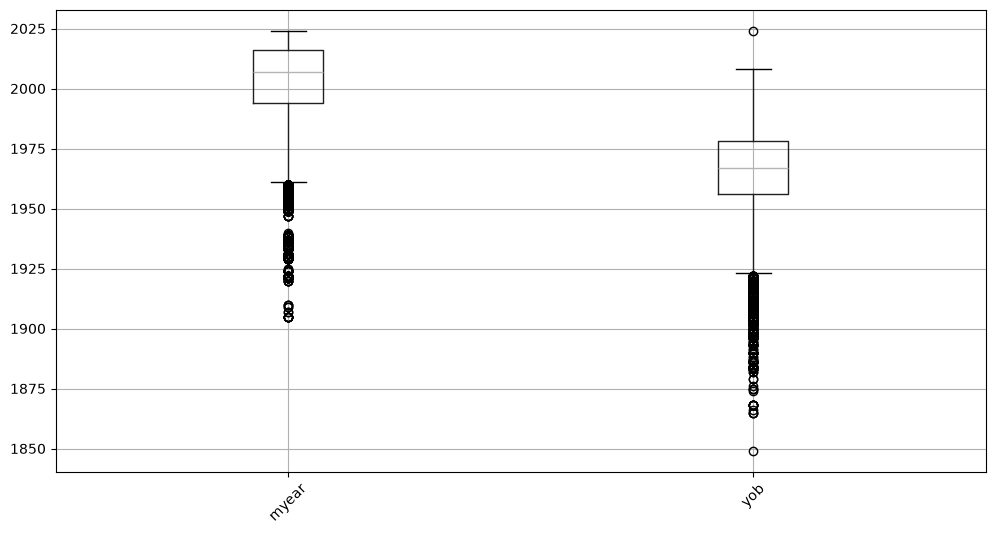

[1905 1907 1909 1910 1920 1921 1922 1924 1925 1929 1930 1931 1933 1934
 1935 1936 1937 1938 1939 1940 1947 1949 1950 1951 1952 1953 1954 1955
 1956 1957 1958 1959 1960 1961 1962 1963 1964 1965 1966 1967 1968 1969
 1970 1971 1972 1973 1974 1975 1976 1977 1978 1979 1980 1981 1982 1983
 1984 1985 1986 1987 1988 1989 1990 1991 1992 1993 1994 1995 1996 1997
 1998 1999 2000 2001 2002 2003 2004 2005 2006 2007 2008 2009 2010 2011
 2012 2013 2014 2015 2016 2017 2018 2019 2020 2021 2022 2023 2024]
[1849. 1865. 1866. 1868. 1874. 1875. 1876. 1879. 1882. 1883. 1884. 1885.
 1886. 1887. 1888. 1890. 1891. 1892. 1893. 1894. 1895. 1896. 1897. 1898.
 1899. 1900. 1901. 1902. 1903. 1904. 1905. 1906. 1907. 1908. 1909. 1910.
 1911. 1912. 1913. 1914. 1915. 1916. 1917. 1918. 1919. 1920. 1921. 1922.
 1923. 1924. 1925. 1926. 1927. 1928. 1929. 1930. 1931. 1932. 1933. 1934.
 1935. 1936. 1937. 1938. 1939. 1940. 1941. 1942. 1943. 1944. 1945. 1946.
 1947. 1948. 1949. 1950. 1951. 1952. 1953. 1954. 1955. 1956. 1957. 19

In [227]:
import matplotlib.pyplot as plt
import numpy as np

num_cols = df.select_dtypes("number").columns

df[num_cols].boxplot(figsize=(12, 6), rot=45)
plt.show()
print(np.sort(df.myear.unique()))
unique_yob = df.yob.unique()
print(np.sort(unique_yob))

Boxplot of all the number features. Only year attempted and year of birth there after removing data leakage and boolean (0,1) columns. There does seem to be an outlier in yob cause by incorrect data entry --> someone born in 2024 can't possible have climbed Everest yet, unless their parents are doing an atrocious job. So I'll have to fix that and replace it with the mean age

In [228]:

def find_age(row):
    age = (row['myear']) - row['yob']
   # if age > 80 or age < 13: #youngest and oldest people to climb a himalayan mountain
    return age


df["age"] = df.apply(find_age, axis=1)
print(np.sort(df.age.unique()))
#print("\n", df["age"].value_counts())


[-51. -50. -48. -45. -43. -42. -41. -40. -39. -38. -37. -36. -35. -34.
 -33. -32. -31. -30. -29. -28. -27. -26. -25. -24. -23. -22. -21. -20.
 -19. -18. -17. -16. -15. -14. -13. -12. -11. -10.  -9.  -8.  -7.  -6.
  -5.  -4.  -3.  -2.  -1.   0.   1.   2.   3.   4.   5.   6.   7.   8.
   9.  10.  11.  12.  13.  14.  15.  16.  17.  18.  19.  20.  21.  22.
  23.  24.  25.  26.  27.  28.  29.  30.  31.  32.  33.  34.  35.  36.
  37.  38.  39.  40.  41.  42.  43.  44.  45.  46.  47.  48.  49.  50.
  51.  52.  53.  54.  55.  56.  57.  58.  59.  60.  61.  62.  63.  64.
  65.  66.  67.  68.  69.  70.  71.  72.  73.  74.  75.  76.  77.  78.
  79.  80.  81.  82.  83.  84.  85.  86.  87.  88.  89.  90.  91.  92.
  93.  95.  96.  97.  98.  99. 100. 101. 102. 103. 104. 105. 107. 109.
 111. 114. 116. 118. 119.  nan]


I've managed to find a large amount of data entry errors where the age isn't possible. The ages are either too large (119 when the oldest person to climb a Himalayan mountain was 80), too young (youngest was 13) or in the minuses. I plan to replace these with NaN for now and then fill them in later in pre-processing.

In [229]:
def replace_age(row):
    age = row['myear'] - row['yob']
    if age > 80 or age < 13: #youngest and oldest people to climb a himalayan mountain
        return None
    return age

df["age"] = df.apply(replace_age, axis=1)
print(np.sort(df.age.unique()))
df = df.drop(columns = ['yob'])

[13. 14. 15. 16. 17. 18. 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30.
 31. 32. 33. 34. 35. 36. 37. 38. 39. 40. 41. 42. 43. 44. 45. 46. 47. 48.
 49. 50. 51. 52. 53. 54. 55. 56. 57. 58. 59. 60. 61. 62. 63. 64. 65. 66.
 67. 68. 69. 70. 71. 72. 73. 74. 75. 76. 77. 78. 79. 80. nan]


removed impossible numbers and yob column, to prevent the yob and age from contradicting each other

In [230]:
df.to_csv('data/cleaned_members.csv', index = False)
print("File Saved")

File Saved
